# Notebook 2: Tokenization and Next-Token Prediction

## From Text to Tokens to Probabilities — Inside a Real Model

Now we'll use **GPT-2** (124M parameters) via HuggingFace Transformers to see the full pipeline:

**Text → Tokens → Model → Logits → Probabilities → Next Token**

We use GPT-2 here (not Ollama) because we need direct access to the model's internal logit tensors. Ollama abstracts this away — great for production, but we want to see the guts.

In [2]:
import torch
import torch.nn.functional as F
from transformers import GPT2LMHeadModel, GPT2Tokenizer
import matplotlib.pyplot as plt
import numpy as np

plt.style.use("seaborn-v0_8-whitegrid")

# Load GPT-2 (small, 124M params — downloads ~500MB on first run)
model_name = "gpt2"
tokenizer = GPT2Tokenizer.from_pretrained(model_name)
model = GPT2LMHeadModel.from_pretrained(model_name)
model.eval()  # Inference mode — no dropout

print(f"Model: {model_name}")
print(f"Parameters: {sum(p.numel() for p in model.parameters()):,}")
print(f"Vocabulary size: {tokenizer.vocab_size:,}")

/Users/nijjohnson/Projects/token-probabilities/.venv/lib/python3.14/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
Loading weights: 100%|██████████| 148/148 [00:00<00:00, 21374.46it/s]

Model: gpt2
Parameters: 124,439,808
Vocabulary size: 50,257


## Step 1: Tokenization

LLMs don't see characters or words — they see **tokens**. Tokenization splits text into subword units from a fixed vocabulary.

GPT-2 uses **Byte-Pair Encoding (BPE)**:
- Common words are single tokens: "the" → `[the]`
- Rare words get split: "tokenization" → `[token, ization]`
- Every possible text can be encoded (no "unknown" tokens)

In [3]:
# Tokenization examples
examples = [
    "The cat sat on the mat",
    "Machine learning is fascinating",
    "supercalifragilisticexpialidocious",
    "GPT-2 uses byte-pair encoding",
    "def hello_world():",
]

for text in examples:
    token_ids = tokenizer.encode(text)
    tokens = [tokenizer.decode([tid]) for tid in token_ids]
    print(f'"{ text}"')
    print(f"  Token IDs: {token_ids}")
    print(f"  Tokens:    {tokens}")
    print(f"  Count:     {len(token_ids)} tokens")
    print()

"The cat sat on the mat"
  Token IDs: [464, 3797, 3332, 319, 262, 2603]
  Tokens:    ['The', ' cat', ' sat', ' on', ' the', ' mat']
  Count:     6 tokens

"Machine learning is fascinating"
  Token IDs: [37573, 4673, 318, 13899]
  Tokens:    ['Machine', ' learning', ' is', ' fascinating']
  Count:     4 tokens

"supercalifragilisticexpialidocious"
  Token IDs: [16668, 9948, 361, 22562, 346, 396, 501, 42372, 498, 312, 32346]
  Tokens:    ['super', 'cal', 'if', 'rag', 'il', 'ist', 'ice', 'xp', 'ial', 'id', 'ocious']
  Count:     11 tokens

"GPT-2 uses byte-pair encoding"
  Token IDs: [38, 11571, 12, 17, 3544, 18022, 12, 24874, 21004]
  Tokens:    ['G', 'PT', '-', '2', ' uses', ' byte', '-', 'pair', ' encoding']
  Count:     9 tokens

"def hello_world():"
  Token IDs: [4299, 23748, 62, 6894, 33529]
  Tokens:    ['def', ' hello', '_', 'world', '():']
  Count:     5 tokens



## Step 2: Forward Pass — Getting Logits from the Model

The model takes token IDs as input and outputs logits for **every position** in the sequence. At each position, the model predicts the **next** token.

For a sequence of $n$ tokens, the model outputs an $n \times V$ matrix of logits, where $V$ is the vocabulary size. The logits at position $i$ represent the model's prediction for position $i+1$.

In [4]:
prompt = "The capital of France is"

# Tokenize
input_ids = tokenizer.encode(prompt, return_tensors="pt")  # pt = PyTorch tensor
tokens_in = [tokenizer.decode([tid]) for tid in input_ids[0]]

print(f'Prompt: "{prompt}"')
print(f"Token IDs: {input_ids[0].tolist()}")
print(f"Tokens: {tokens_in}")
print(f"Input shape: {input_ids.shape}  (batch_size=1, sequence_length={input_ids.shape[1]})")

# Forward pass — no gradient computation needed for inference
with torch.no_grad():
    outputs = model(input_ids)
    logits = outputs.logits

print(f"\nOutput logits shape: {logits.shape}")
print(f"  → batch_size={logits.shape[0]}, sequence_length={logits.shape[1]}, vocab_size={logits.shape[2]}")
print(f"\nAt each of the {logits.shape[1]} positions, the model produces {logits.shape[2]:,} logits (one per vocab token)")

Prompt: "The capital of France is"
Token IDs: [464, 3139, 286, 4881, 318]
Tokens: ['The', ' capital', ' of', ' France', ' is']
Input shape: torch.Size([1, 5])  (batch_size=1, sequence_length=5)

Output logits shape: torch.Size([1, 5, 50257])
  → batch_size=1, sequence_length=5, vocab_size=50257

At each of the 5 positions, the model produces 50,257 logits (one per vocab token)


## Step 3: From Logits to Next-Token Probabilities

We care about the logits at the **last position** — these predict the next token after our prompt.

In [5]:
# Get logits for the LAST token position (predicts what comes next)
next_token_logits = logits[0, -1, :]  # shape: [vocab_size]
print(f"Next-token logits shape: {next_token_logits.shape}")
print(f"Logit range: [{next_token_logits.min():.2f}, {next_token_logits.max():.2f}]")

# Apply softmax to get probabilities
next_token_probs = F.softmax(next_token_logits, dim=0)

# Top 15 most likely next tokens
top_k = 15
top_probs, top_indices = torch.topk(next_token_probs, top_k)

print(f'\n=== Top {top_k} predictions for: "{prompt} ___" ===\n')
print(f"{"Rank":>4s}  {"Token":>12s}  {"Token ID":>8s}  {"Prob":>8s}  {"Log-Prob":>10s}")
print("-" * 52)
for rank, (prob, idx) in enumerate(zip(top_probs, top_indices), 1):
    token_str = tokenizer.decode([idx]).replace("\n", "\\n")
    log_prob = torch.log(prob).item()
    print(f"{rank:4d}  {token_str:>12s}  {idx:8d}  {prob:8.4f}  {log_prob:10.4f}")

print(f"\nTop {top_k} tokens capture {top_probs.sum():.1%} of total probability mass")

Next-token logits shape: torch.Size([50257])
Logit range: [-129.87, -100.25]

=== Top 15 predictions for: "The capital of France is ___" ===

Rank         Token  Token ID      Prob    Log-Prob
----------------------------------------------------
   1           the       262    0.0846     -2.4699
   2           now       783    0.0479     -3.0376
   3             a       257    0.0462     -3.0756
   4        France      4881    0.0324     -3.4303
   5         Paris      6342    0.0322     -3.4344
   6            in       287    0.0266     -3.6253
   7          also       635    0.0264     -3.6341
   8           not       407    0.0238     -3.7369
   9          home      1363    0.0233     -3.7572
  10         still       991    0.0155     -4.1664
  11         under       739    0.0142     -4.2510
  12       located      5140    0.0139     -4.2729
  13            on       319    0.0134     -4.3134
  14           one       530    0.0113     -4.4834
  15         known      1900    0.0094  

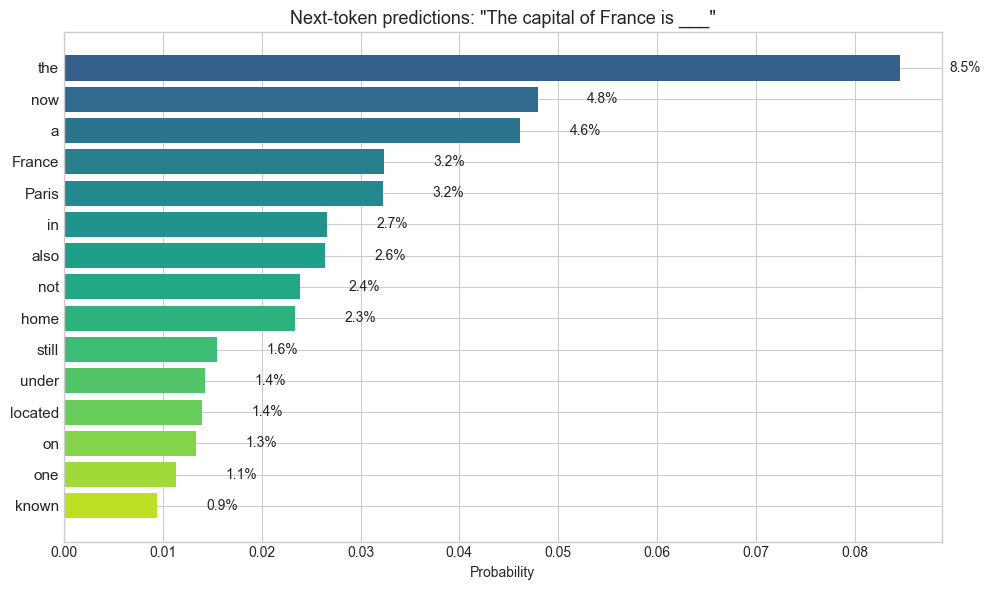

In [6]:
# Visualize the top predictions
fig, ax = plt.subplots(figsize=(10, 6))

token_labels = [tokenizer.decode([idx]).strip() for idx in top_indices]
colors = plt.cm.viridis(np.linspace(0.3, 0.9, top_k))

bars = ax.barh(range(top_k), top_probs.numpy(), color=colors)
ax.set_yticks(range(top_k))
ax.set_yticklabels(token_labels, fontsize=11)
ax.invert_yaxis()
ax.set_xlabel("Probability")
ax.set_title(f'Next-token predictions: "{prompt} ___"', fontsize=13)

for bar, prob in zip(bars, top_probs):
    ax.text(bar.get_width() + 0.005, bar.get_y() + bar.get_height() / 2,
            f"{prob:.1%}", va="center", fontsize=10)

plt.tight_layout()
plt.show()

## Predictions at Every Position

The model doesn't just predict the last token — it predicts the next token at **every** position in the input. Let's look at what the model predicts after each token in our prompt.

In [7]:
# Show predictions at every position
print(f'Prompt: "{prompt}"\n')
print(f"{"Position":>8s}  {"Input Token":>14s}  {"Predicts Next":>14s}  {"Prob":>8s}  {"Actual Next":>14s}  {"Match":>5s}")
print("-" * 75)

all_probs = F.softmax(logits[0], dim=-1)  # [seq_len, vocab_size]

for pos in range(input_ids.shape[1]):
    input_token = tokenizer.decode([input_ids[0, pos]])
    
    # What does the model predict for position pos+1?
    pred_prob, pred_idx = all_probs[pos].max(dim=0)
    predicted_token = tokenizer.decode([pred_idx])
    
    # What actually comes next?
    if pos < input_ids.shape[1] - 1:
        actual_next = tokenizer.decode([input_ids[0, pos + 1]])
        match = "\u2713" if pred_idx == input_ids[0, pos + 1] else "\u2717"
    else:
        actual_next = "(to generate)"
        match = "\u2014"
    
    print(f"{pos:8d}  {input_token:>14s}  {predicted_token:>14s}  {pred_prob:8.1%}  {actual_next:>14s}  {match:>5s}")

Prompt: "The capital of France is"

Position     Input Token   Predicts Next      Prob     Actual Next  Match
---------------------------------------------------------------------------
       0             The               
      1.4%         capital      ✗
       1         capital              of     16.4%              of      ✓
       2              of             the     23.9%          France      ✗
       3          France               ,     37.5%              is      ✗
       4              is             the      8.5%   (to generate)      —


## Try Different Prompts

Let's build a reusable function and explore how the model's confidence varies with different prompts.

In [8]:
def predict_next(prompt, top_k=10):
    """Show top-k next token predictions for a prompt."""
    input_ids = tokenizer.encode(prompt, return_tensors="pt")
    with torch.no_grad():
        logits = model(input_ids).logits[0, -1, :]
    
    probs = F.softmax(logits, dim=0)
    top_probs, top_indices = torch.topk(probs, top_k)
    
    print(f'"{ prompt}" \u2192 ___\n')
    for rank, (prob, idx) in enumerate(zip(top_probs, top_indices), 1):
        token = tokenizer.decode([idx]).replace("\n", "\\n")
        bar = "\u2588" * int(prob * 50)
        print(f"  {rank:2d}. {token:>15s}  {prob:6.1%}  {bar}")
    print()

# High confidence — factual completions
predict_next("The Eiffel Tower is located in")
predict_next("Water freezes at")

# Lower confidence — open-ended prompts
predict_next("I think the best")
predict_next("Once upon a")

"The Eiffel Tower is located in" → ___

   1.             the   39.7%  ███████████████████
   2.               a    7.5%  ███
   3.         central    2.6%  █
   4.        downtown    2.2%  █
   5.              an    2.2%  █
   6.          London    1.7%  
   7.           front    1.6%  
   8.             New    1.2%  
   9.       Manhattan    1.2%  
  10.             one    1.0%  

"Water freezes at" → ___

   1.             the    8.4%  ████
   2.               a    6.7%  ███
   3.           about    4.4%  ██
   4.           least    2.5%  █
   5.               1    2.2%  █
   6.              an    2.2%  █
   7.           night    1.8%  
   8.          around    1.7%  
   9.              10    1.7%  
  10.               2    1.4%  

"I think the best" → ___

   1.             way   32.8%  ████████████████
   2.           thing   15.1%  ███████
   3.            part    2.5%  █
   4.      compliment    1.6%  
   5.           place    1.5%  
   6.         example    1.4%  
   7.        

## Key Takeaways

1. **Tokenization** splits text into subword units — not characters, not whole words
2. The model outputs logits for the **entire vocabulary** at every position in the sequence
3. For next-token prediction, we take the logits at the **last position** and apply softmax
4. Model **confidence varies** with context: factual completions tend to be peaked, open-ended prompts are flatter
5. Even GPT-2 (124M params) has reasonable intuitions about common completions

**Next up:** How do we actually *choose* a token from this distribution? That's sampling.